# Telco Customer Churn
**Group project · Federico Poi**  
MSCS-634-M50 Advanced Big Data and Data Mining  
Project Deliverable 1 · Data Collection, Cleaning, and Exploration

The IBM Telco Churn sample has 7,043 rows and 21 columns, with one row per customer. Tenure is the number of months a customer has been with the company. Monthly charges are the customer's monthly bill, and total charges are cumulative. A value of `Yes` in `Churn` means the customer left within the last month.

We chose this dataset because it gives us several questions to explore using the same customer records. We can estimate monthly charges, model churn, group similar customers, and look for services and account attributes that occur together. Since the data is a snapshot, we interpret the findings as relationships within the sample.

The loading cell downloads the IBM CSV automatically in Colab. For an offline run, place a copy named `Telco-Customer-Churn.csv` beside the notebook.

[Kaggle dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) · [IBM CSV](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv)

## 1. Load and inspect the data

In [1]:
# Import tools for finding the CSV, inspecting tables, and plotting.
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style="whitegrid")
# Use a local copy if it exists. Otherwise load the CSV directly from IBM.
source_url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
local_csv = Path("Telco-Customer-Churn.csv")
raw = pd.read_csv(local_csv if local_csv.is_file() else source_url)

# Check the dataset size, sample records, and column types before cleaning.
print(f"Raw data: {raw.shape[0]:,} rows and {raw.shape[1]} columns")
display(raw.head())
raw.info()
# Count recognized missing values and check the balance of the churn label.
display(raw.isna().sum().rename("Raw nulls").to_frame())
display(raw["Churn"].value_counts().rename("Customers").to_frame())

Matplotlib is building the font cache; this may take a moment.


Raw data: 7,043 rows and 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,Raw nulls
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


,Customers
Churn,
No,5174
Yes,1869


## 2. Handle missing values
Spaces in `TotalCharges` can slip past the initial missing-value count. We trim the text before converting the column to numbers and check whether anything besides the blanks fails to convert.

In [2]:
# Clean a copy so the original data is available for comparison.
df = raw.copy()
# Trim billing text so entries containing only spaces can be counted as blanks.
total_text = df["TotalCharges"].astype("string").str.strip()
blank_totals = total_text.eq("").fillna(False)
# Convert billing totals to numbers. Leave blanks missing because their billed amount is unknown.
df["TotalCharges"] = pd.to_numeric(total_text, errors="coerce")

# Check whether any nonblank text also failed to convert.
unexpected = total_text.notna() & ~blank_totals & df["TotalCharges"].isna()
print("Whitespace-only totals:", blank_totals.sum())
print("Unexpected nonnumeric totals:", unexpected.sum())
# See whether missing billing totals are concentrated at a particular tenure.
print("Customers with missing totals by tenure:")
display(df.loc[df["TotalCharges"].isna(), "tenure"].value_counts().to_frame("Customers"))
# List columns that still have missing values after conversion.
display(df.isna().sum().loc[lambda counts: counts.gt(0)].to_frame("Missing after conversion"))

Whitespace-only totals: 11
Unexpected nonnumeric totals: 0
Customers with missing totals by tenure:


,Customers
tenure,
0,11


,Missing after conversion
TotalCharges,11


All 11 missing billing totals belong to customers with zero months of tenure. We left those totals as `NaN` because the actual amounts are unknown. The customers' other fields are still usable, so we kept all 11 in the main dataset and used the 7,032 recorded totals for billing analysis that needs this field.

## 3. Check duplicates and formatting

In [3]:
# Trim extra spaces so they do not affect label or duplicate checks.
for column in df.select_dtypes(include=["object", "string"]).columns:
    df[column] = df[column].str.strip()

# Count and remove rows that are identical across every column.
duplicate_rows = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
# Check whether any customer ID still appears more than once.
repeated_ids = df["customerID"].duplicated(keep=False)
print("Exact duplicate rows removed:", duplicate_rows)
print("Rows with a repeated customer ID:", repeated_ids.sum())
print("Missing customer IDs:", df["customerID"].isna().sum())
# Review distinct category labels for inconsistent spelling or formatting.
for column in ["Churn", "Contract", "InternetService", "MultipleLines"]:
    print(f"{column}: {sorted(df[column].dropna().unique())}")

# Use recorded totals in cumulative-charge plots and keep all customers in the main table.
billing_df = df.dropna(subset=["TotalCharges"]).copy()
print(f"Customers retained: {len(df):,}")
print(f"Customers with observed total charges: {len(billing_df):,}")

Exact duplicate rows removed: 0
Rows with a repeated customer ID: 0
Missing customer IDs: 0
Churn: ['No', 'Yes']
Contract: ['Month-to-month', 'One year', 'Two year']
InternetService: ['DSL', 'Fiber optic', 'No']
MultipleLines: ['No', 'No phone service', 'Yes']
Customers retained: 7,043
Customers with observed total charges: 7,032


We found no exact duplicate rows or repeated customer IDs, so we removed no records. Labels such as `No internet service` describe a customer's service status and stay as recorded.

## 4. Check for noisy values
We checked billing and tenure for negative values. For monthly bills, we used the 1.5 × IQR rule to flag charges for closer review.

In [4]:
# Review numeric ranges and count negative values in tenure and billing.
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
display(df[numeric_columns].describe().round(2))
display(df[numeric_columns].lt(0).sum().rename("Negative values").to_frame())

monthly = df["MonthlyCharges"]
# Compute the quartiles and IQR to measure the spread of the middle half of monthly bills.
q1, q3 = monthly.quantile([0.25, 0.75])
iqr = q3 - q1
# Flag charges beyond 1.5 times the IQR from either quartile for review.
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
overall_flags = monthly.lt(lower) | monthly.gt(upper)
print(f"Overall IQR fences: {lower:.2f} to {upper:.2f}")
print("Monthly charges outside the overall fences:", overall_flags.sum())

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.0
mean,32.37,64.76,2283.3
std,24.56,30.09,2266.77
min,0.00,18.25,18.8
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.8


,Negative values
tenure,0
MonthlyCharges,0
TotalCharges,0


Overall IQR fences: -46.02 to 171.38
Monthly charges outside the overall fences: 0


We found no negative values and no monthly charges outside the overall IQR fences of −46.02 and 171.38. The lower fence is negative because of how the rule is calculated. We focused the IQR check on monthly charges because high tenure can reflect long-standing customers and cumulative charges depend on how long customers have been billed, so we reviewed tenure’s range and plotted total charges against tenure. We kept the values and looked at charges within each service group as well, since the billing ranges vary by service type.

## 5. Explore distributions and relationships
### Tenure and monthly charges

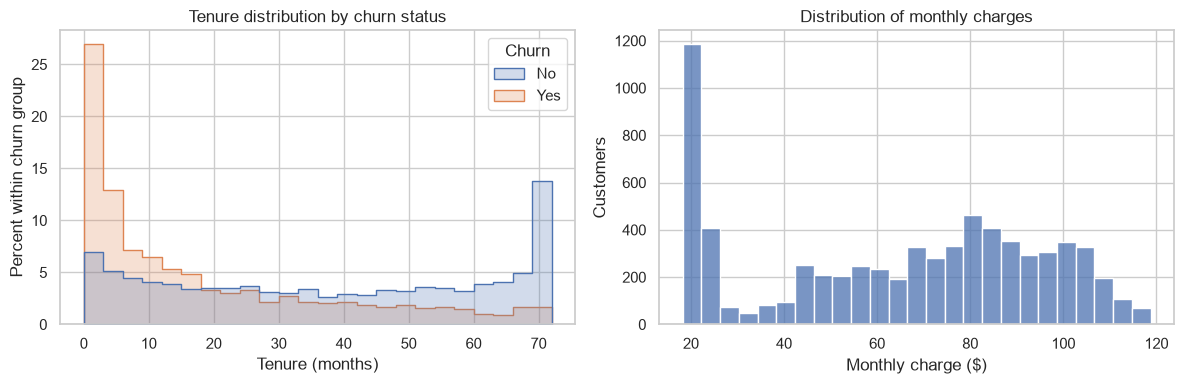

In [5]:
# Place the tenure and monthly charge distributions side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Calculate percentages separately for each churn group so their shapes are comparable.
sns.histplot(data=df, x="tenure", hue="Churn", bins=24, stat="percent",
             common_norm=False, element="step", ax=axes[0])
axes[0].set(title="Tenure distribution by churn status", xlabel="Tenure (months)",
            ylabel="Percent within churn group")
# Count customers in each billing range to show where monthly charges concentrate.
sns.histplot(data=df, x="MonthlyCharges", bins=25, ax=axes[1])
axes[1].set(title="Distribution of monthly charges", xlabel="Monthly charge ($)",
            ylabel="Customers")
plt.tight_layout()
plt.show()

About 27% of customers who churned fell in the shortest tenure bin, compared with about 7% of customers who stayed. Each percentage uses its own churn group as the denominator. We’ll test whether tenure helps predict churn.

Monthly bills show a sharp peak near 20 dollars and a broader concentration between 65 and 105 dollars. We compared bills by internet service to see how those price ranges line up with the services customers have.

### Monthly charges by internet service

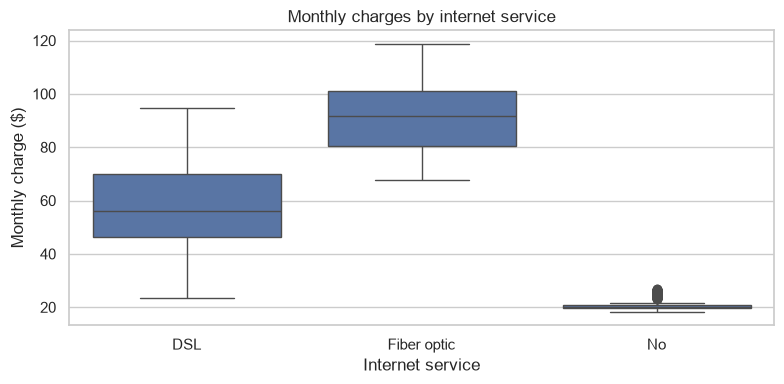

,customers,median,lowest,highest
InternetService,,,,
DSL,2421,56.150,23.45,94.80
Fiber optic,3096,91.675,67.75,118.75
No,1526,20.150,18.25,26.90


Flagged customers in the no-internet group: 342


,,customers,lowest,highest
PhoneService,MultipleLines,,,
Yes,Yes,342,22.95,26.9


In [6]:
# Compare the median, spread, and potential outliers in each internet service group.
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="InternetService", y="MonthlyCharges", ax=ax)
ax.set(title="Monthly charges by internet service", xlabel="Internet service",
       ylabel="Monthly charge ($)")
plt.tight_layout()
plt.show()

# Print the group sizes and charge summaries alongside the plot.
display(df.groupby("InternetService")["MonthlyCharges"]
          .agg(customers="size", median="median", lowest="min", highest="max"))

# Check whether the flagged bills share the same phone service setup.
no_internet = df.loc[df["InternetService"].eq("No")]
charges = no_internet["MonthlyCharges"]
# Calculate IQR fences within the no-internet group, which has its own billing range.
group_q1, group_q3 = charges.quantile([0.25, 0.75])
group_iqr = group_q3 - group_q1
flagged = no_internet.loc[
    charges.lt(group_q1 - 1.5 * group_iqr) | charges.gt(group_q3 + 1.5 * group_iqr)
]
print("Flagged customers in the no-internet group:", len(flagged))
# Summarize the flagged bills by phone service and multiple-line status.
display(flagged.groupby(["PhoneService", "MultipleLines"])["MonthlyCharges"]
               .agg(customers="size", lowest="min", highest="max"))

The median monthly bill was about 92 dollars for fiber optic customers, 56 dollars for DSL customers, and 20 dollars for customers without internet. The IQR rule flagged 342 customers within the no-internet group. Every one had phone service with multiple lines, and their bills ranged from 22.95 to 26.90 dollars. That shared service setup offers a plausible explanation for the higher bills, so we kept all 342 records. We’ll test `InternetService` and `MultipleLines` in our monthly charge models.

### Total charges and tenure

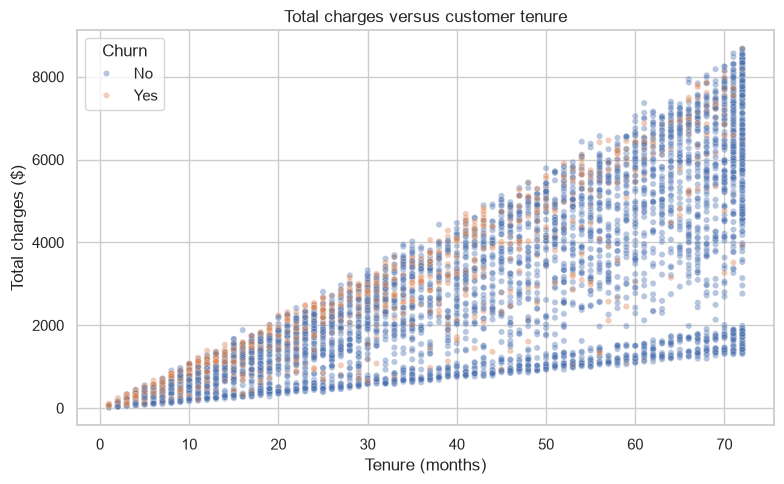

In [7]:
# Plot reported cumulative charges against tenure to examine how charges build over time.
fig, ax = plt.subplots(figsize=(8, 5))
# Color points by churn status and use transparency so overlapping customers are visible.
sns.scatterplot(data=billing_df, x="tenure", y="TotalCharges", hue="Churn",
                alpha=0.4, s=20, ax=ax)
ax.set(title="Total charges versus customer tenure", xlabel="Tenure (months)",
       ylabel="Total charges ($)")
plt.tight_layout()
plt.show()

Total charges generally rose with tenure, and the spread widened among customers who had been with the company longer. The two churn groups overlapped. We’ll compare churn models with and without `TotalCharges` to see whether it adds information beyond tenure. For the monthly charge regression, we’ll exclude cumulative charges and fields calculated from them because they can indirectly reveal the monthly amount.

### Churn by contract type

,customers,churned,churn_pct
Contract,,,
Month-to-month,3875,1655,42.7
One year,1473,166,11.3
Two year,1695,48,2.8


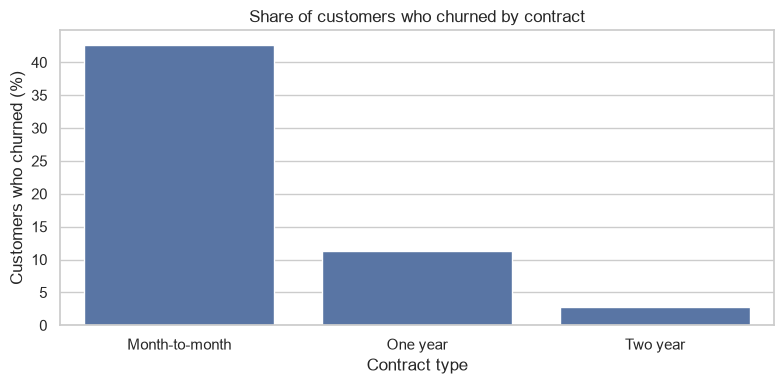

In [8]:
# Use the share who churned within each contract group so group size does not drive the comparison.
contract_summary = (
    df.assign(churned=df["Churn"].eq("Yes"))
      .groupby("Contract")["churned"]
      .agg(customers="size", churned="sum", churn_rate="mean")
      .sort_values("churn_rate", ascending=False)
)
# Convert each within-contract rate to a percentage and show its underlying counts.
contract_summary["churn_pct"] = 100 * contract_summary["churn_rate"]
display(contract_summary[["customers", "churned", "churn_pct"]].round(1))

# Plot the precomputed percentages so contract groups can be compared directly.
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=contract_summary.reset_index(), x="Contract", y="churn_pct", ax=ax)
ax.set(title="Share of customers who churned by contract", xlabel="Contract type",
       ylabel="Customers who churned (%)")
plt.tight_layout()
plt.show()

About 43% of customers on month-to-month contracts churned. The shares were about 11% on one-year contracts and 3% on two-year contracts. We’ll test contract type alongside tenure and other account features because those differences could also help explain the gap.

## 6. What we will carry into modeling

- For regression, we’ll estimate `MonthlyCharges` using service features such as `InternetService` and `MultipleLines`.
- For classification, we’ll use `Churn` as the outcome and start with tenure, contract type, and services. About 26.5% of customers churned, so we’ll use stratified splits and report F1 and ROC-AUC alongside accuracy. If we include `TotalCharges`, we’ll handle missing values within the training pipeline.
- For clustering and association rules, we’ll leave out `customerID`. We’ll scale numeric features for distance-based clustering and use service and account categories to build customer itemsets for rule mining.

The cleaned table has all 7,043 customers. We used the 7,032 recorded cumulative charges for the analysis that required them.